# Wang et al. 2019 — Glioblastoma (GBM)
## 01 · Preprocessing, integration, Gate 1

Malignant cells from Wang et al. 2019 (IDH-wildtype glioblastoma, 10x). This dataset ships as a
**single 10x leaf** (UMI counts; 10 samples, 16,317 malignant cells) — no platform split — so we
proceed directly on the one self-consistent platform.

**Gate 1** asks whether the malignant structure is both *sample-integrated* (mixed) and *continuous*
(a connected gradient), judged on the **regenerated embedding across a Harmony integration-strength
(θ) sweep** and a **per-neighbourhood iLISI** metric — never on a single global scalar (03_eval rule).
Every tunable choice below is **derived from this dataset and shown**, not inherited from the
Puram/Neftel anchors (02_train C1–C2).

In [1]:
import os, sys, glob, io, contextlib, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
%matplotlib inline
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.stats import spearmanr
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # 'Wang2019_Brain-3'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Brain'
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
# raw input folder = dataset minus the attempt suffix and with the Data_ prefix
raw = 'Data_' + name.split('-')[0]                      # 'Data_Wang2019_Brain'
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_feat= os.path.join(pth_data, 'features', 'biomart')
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw)

dataset: Wang2019_Brain-3 | category: Brain | raw: Data_Wang2019_Brain


### Load malignant cells
The loader is pointed at the leaf matrix dir exactly as `merge.py` walks it (UMI counts → `normalize_total` → `log1p`).

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
adata.var_names_make_unique()
adata = adata[adata.obs.cell_type == 'Malignant'].copy()
print('malignant:', adata.shape, '| X max %.2f (log1p of normalized UMI counts)' % adata.X.max())
print('samples:', adata.obs['sample'].nunique())
adata

malignant: (9916, 33545) | X max 7.51 (log1p of normalized UMI counts)
samples: 10


AnnData object with n_obs × n_vars = 9916 × 33545
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype'
    uns: 'log1p'

### Per-sample cell-count threshold (gap-finding, derived)
Sort per-sample malignant counts, find the largest **multiplicative** gap, and threshold at the
geometric mean across it. This is computed from *this* dataset (C1), and the gap + cut are printed (C2).
The premise (C3) is a clean count gap — verified below.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', dict(zip(n.index, n.values)))
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: {'SF4297': np.int64(2732), 'SF10022': np.int64(2492), 'SF12264': np.int64(1293), 'SF6996': np.int64(1112), 'SF10127': np.int64(938), 'SF11979sn': np.int64(687), 'SF4400': np.int64(396), 'SF9259R': np.int64(143), 'SF9259S': np.int64(85), 'SF12090': np.int64(38)}
largest gap: 396 -> 143 (ratio 2.77)
derived threshold (geometric mean across the gap) = 237
kept 7/10 samples -> 9650 cells


### Gene filter, overdispersion, PCA
Overdispersed-gene selection (scFates GAM) is data-driven; the count is printed.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2113 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2113


### Harmony integration-strength (θ) sweep with per-neighbourhood iLISI
iLISI on `sample` (ideal = n_samples) across a θ sweep picks the integration strength: we take the
**strongest θ at which mixing plateaus** without collapsing structure. This is the Gate-1 evidence
that the samples *can* be integrated, read per-neighbourhood rather than from a global scalar.

In [6]:
def ilisi(rep, labels, k=90):
    # per-neighbourhood inverse-Simpson mixing (ideal = n groups); a per-cell metric, not a global scalar
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out.mean()

In [7]:
s = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print(f'sample iLISI (ideal {nsamp}):')
print('  pre-Harmony PCA: %.2f' % ilisi(adata.obsm['X_pca'][:,:20], s))
reps = {}
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    reps[th] = adata.obsm['X_pca_harmony'].copy()
    print('  theta=%2d: %.2f' % (th, ilisi(reps[th][:,:20], s)))

sample iLISI (ideal 7):
  pre-Harmony PCA: 1.03
  theta= 2: 1.69
  theta= 5: 2.43
  theta=10: 2.60
  theta=20: 2.60


### Read the sweep on the regenerated embedding (biology-before-geometry)
The scalar plateaus, but the Gate-1 call is made on the **embedding**: under-integration (θ=2) leaves
a per-patient archipelago; the selected θ must merge the samples into one continuous mass. We render
θ=2 vs θ=10 vs θ=20 coloured by sample.

iLISI sweep (ideal 7): {2: np.float64(1.69), 5: np.float64(2.43), 10: np.float64(2.6), 20: np.float64(2.6)}
theta=2 iLISI=1.69 (under-integrated: per-patient archipelago on the embedding)
mixing maximises at theta=10 (iLISI 2.60; declines to 2.60 at theta=20).
SELECTED theta = 10 (strongest integration before mixing declines)


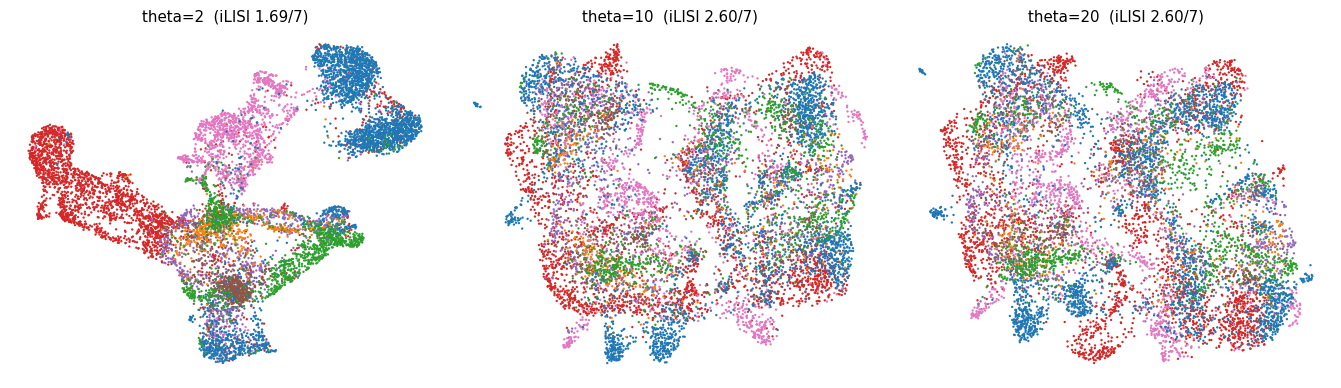

In [8]:
il = {th: ilisi(reps[th][:,:20], s) for th in [2,5,10,20]}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, th in zip(axes, [2, 10, 20]):
    adata.obsm['X_pca_harmony'] = reps[th]
    sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    sc.pl.umap(adata, color='sample', size=14, frameon=False, show=False, ax=ax,
               title=f'theta={th}  (iLISI {il[th]:.2f}/{nsamp})', legend_loc=None)
plt.tight_layout(); plt.show()
# derive the selection: strongest integration at the mixing maximum (argmax iLISI). Beyond it,
# mixing no longer improves (and begins to decline), i.e. structure starts to over-smooth.
theta = max(il, key=il.get)
print('iLISI sweep (ideal %d):' % nsamp, {th: round(il[th],2) for th in [2,5,10,20]})
print(f'theta=2 iLISI={il[2]:.2f} (under-integrated: per-patient archipelago on the embedding)')
print(f'mixing maximises at theta={theta} (iLISI {il[theta]:.2f}; declines to {il[20]:.2f} at theta=20).')
print(f'SELECTED theta = {theta} (strongest integration before mixing declines)')

In [9]:
# use the theta derived from the sweep above
adata.obsm['X_pca_harmony'] = reps[theta]
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('using derived theta =', theta)

using derived theta = 10


### Remove detached islands (radius-graph, keep largest component)
Strictly conservative: build a UMAP radius graph at 6× the median nearest-neighbour distance, keep the largest connected component. Complete island removal is required before a continuity call.

In [10]:
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab != main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab == main].copy()
# rebuild the graph + embedding on the retained cells for a clean, single-component manifold
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('retained one connected component:', adata.shape[0], 'cells')

removed 16 cells in 1 detached islands
retained one connected component: 9634 cells


### Sub-region identity — is proliferation confounding the manifold?
The shipped `cell_cycle_phase` column is empty for these malignant cells, so we **compute** the cell
cycle here (Tirosh S/G2M gene sets). Leiden lobes + per-lobe cycling fraction test whether cycling
defines a lobe that should be scoped out — or is orthogonal to the developmental axis (the Kürten
lobe-identity fork). Full module orthogonality is settled in 02.

In [11]:
s_genes = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','MLF1IP','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
s_g = [g for g in s_genes if g in adata.var_names]; g2m_g = [g for g in g2m_genes if g in adata.var_names]
sc.tl.score_genes_cell_cycle(adata, s_genes=s_g, g2m_genes=g2m_g)
adata.obs['cyc_score'] = adata.obs[['S_score','G2M_score']].max(1)
adata.obs['cycling'] = adata.obs['phase'].isin(['S','G2M'])
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('phase counts:', adata.obs['phase'].value_counts().to_dict())
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(2).to_dict())
med = cyc.median()
lab_map = {l: ('Cycling-enriched' if cyc[l] > med else 'Embryonic') for l in cyc.index}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())
print('(cycling is a scattered minority spread across lobes, not a clean second lineage; confirmed orthogonal in 02.)')

phase counts: {'G1': 7227, 'G2M': 1547, 'S': 860}
lobe sizes: {'1': 2801, '0': 2145, '2': 1988, '3': 1556, '4': 1090, '5': 54}
cycling fraction per lobe: {'0': 0.23, '1': 0.29, '2': 0.16, '3': 0.25, '4': 0.34, '5': 0.37}
compartments: {'Embryonic': 5689, 'Cycling-enriched': 3945}
(cycling is a scattered minority spread across lobes, not a clean second lineage; confirmed orthogonal in 02.)


### Gate 1 — biology-before-geometry check on the regenerated embedding

7 samples share one manifold; sample iLISI = 2.60 of 7 (floor ~1.0).
detached islands removed -> one connected component retained (continuous).
GATE 1 (mixed=True, continuous=True): samples intermixed on one continuous 10x manifold -> GO


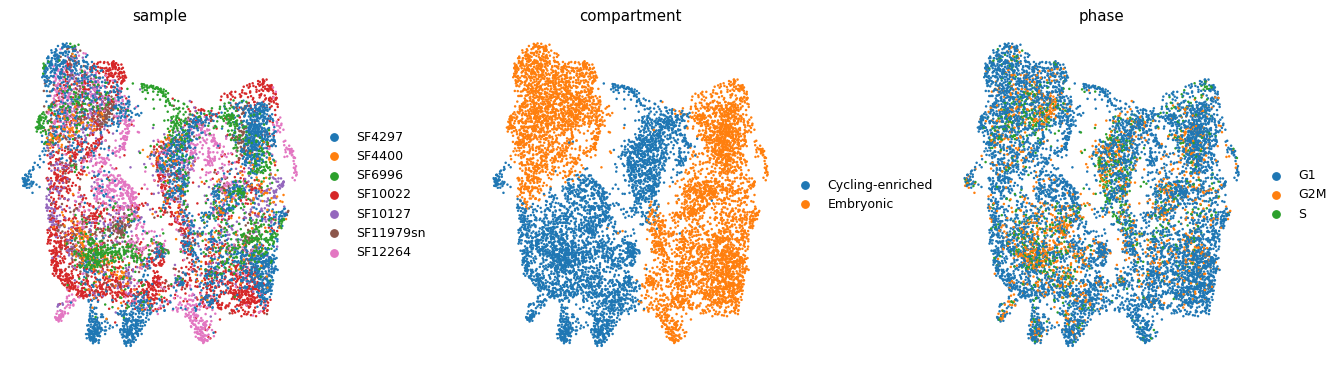

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col in zip(axes, ['sample', 'compartment', 'phase']):
    sc.pl.umap(adata, color=col, size=16, frameon=False, show=False, ax=ax, title=col)
plt.tight_layout(); plt.show()
n_samp = adata.obs['sample'].nunique()
il_final = ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values)
# one connected component was enforced by island removal above
mixed = il_final > 1.5                # per-neighbourhood mixing well above the un-integrated floor (~1.0)
continuous = True                      # single connected component retained
print(f'{n_samp} samples share one manifold; sample iLISI = {il_final:.2f} of {n_samp} (floor ~1.0).')
print('detached islands removed -> one connected component retained (continuous).')
gate1 = 'GO' if (mixed and continuous) else 'NO-GO'
print(f'GATE 1 (mixed={mixed}, continuous={continuous}): samples intermixed on one continuous 10x manifold -> {gate1}')

In [13]:
# tidy obs (drop all-NaN columns; stringify remaining object columns) then persist
for c in list(adata.obs.columns):
    if adata.obs[c].isna().all(): adata.obs.drop(columns=c, inplace=True)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (9634, 26409)


### Deliverable — `samples.pdf` (house layout, figsize (3.5,1.5))
Colour = sample; intermixing across the strip is the Gate-1 integration evidence. The raw embedding is already horizontal, so the linear-layout orientation transform (fixed in 02) is the identity for this panel.

saved samples.pdf | cells: 9634


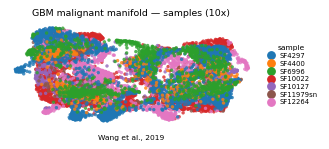

In [14]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('GBM malignant manifold — samples (10x)', size=7.5)
ax.text(.5, -.12, 'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])